In [ ]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px

In [ ]:
train_df=pd.read_excel('train.xlsx')

In [ ]:
display(train_df.head(6))

,PassengerId,Survived,Pclass,Name,Gender,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q


In [ ]:
print("First Few Rows of tain_df:")
print(train_df.head())

First Few Rows of tain_df:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name  Gender   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450  

In [ ]:
print("The number of samples in the train data is {}.".format(train_df.shape[0]))

The number of samples in the train data is 891.


In [ ]:
missing_values_count = train_df.isnull().sum()
print("Number of missing values for each column")
display(missing_values_count)

Number of missing values for each column


,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Gender,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [ ]:
percent_missing_age=(train_df['Age'].isnull().sum()/train_df.shape[0])*100
print(percent_missing_age)

19.865319865319865


In [ ]:
mean_age=train_df['Age'].mean(skipna=True)
print('The mean of "Age" is %.2f'% mean_age)

The mean of "Age" is 29.70


In [ ]:
median_age=train_df['Age'].median(skipna=True)
print('The Median of age" is %.2f'% median_age)

The Median of age" is 28.00


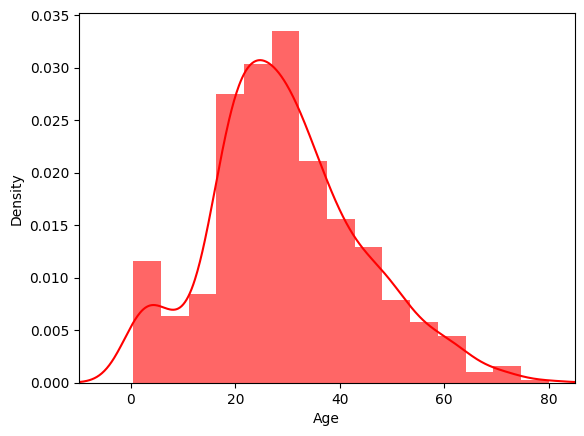

In [ ]:
ax=train_df["Age"].hist(bins=15,density=True,stacked=True,color='red',alpha=0.6)
train_df["Age"].plot(kind='density',color='red')
ax.set(xlabel='Age')
plt.xlim(-10,85)
plt.show()

In [ ]:
percent_missing_embarked=(train_df['Embarked'].isnull().sum()/train_df.shape[0])*100
print(percent_missing_embarked)

0.22446689113355783


In [ ]:
percent_missing_cabin=(train_df['Cabin'].isnull().sum()/train_df.shape[0])*100
print(percent_missing_cabin)

77.10437710437711


In [ ]:
print('Boarded passengers grouped by port of embarkation (C = Cherbourg, Q = Queenstown, S = Southampton):')

# Group passengers by the port of embarkation and count the number of passengers in each group
embarked_counts = train_df['Embarked'].value_counts()

# Print the counts for each port of embarkation
for port, count in embarked_counts.items():
    if port == 'C':
        port_name = 'Cherbourg'
    elif port == 'Q':
        port_name = 'Queenstown'
    elif port == 'S':
        port_name = 'Southampton'
    else:
        port_name = 'Unknown'
    print(f'{port_name}: {count}')

Boarded passengers grouped by port of embarkation (C = Cherbourg, Q = Queenstown, S = Southampton):
Southampton: 644
Cherbourg: 168
Queenstown: 77


Boarded passengers grouped by port of embarkation (C = Cherbourg, Q = Queenstown, S = Southampton):
Embarked
S    644
C    168
Q     77
Name: count, dtype: int64


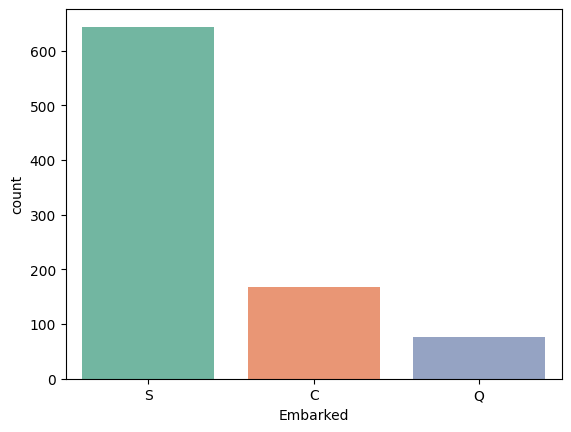

In [ ]:
import seaborn as sns

import matplotlib.pyplot as plt

print('Boarded passengers grouped by port of embarkation (C = Cherbourg, Q = Queenstown, S = Southampton):')

# Print the counts for each port of embarkation

print(train_df['Embarked'].value_counts())

# Create a count plot using seaborn

sns.countplot(x='Embarked', hue='Embarked', data=train_df, palette='Set2', legend=False)

# Set2 predefined color pallet in seaborn

# Show the plot

plt.show()

In [ ]:
most_common_port=train_df['Embarked'].value_counts().idxmax()
print('The most common port of embarkation is:',most_common_port)

The most common port of embarkation is: S


In [ ]:
most_common_port1=train_df['Cabin'].value_counts().idxmax()
print('The most common port of Cabin is:',most_common_port1)

The most common port of Cabin is: G6


In [ ]:
train_data=train_df.copy()
train_data["Age"].fillna(train_data["Age"].median(skipna=True), inplace=True)

/tmp/ipython-input-2476356081.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  train_data["Age"].fillna(train_data["Age"].median(skipna=True), inplace=True)


In [ ]:
train_data["Embarked"].fillna(train_data['Embarked'].value_counts().idxmax(), inplace=True)

/tmp/ipython-input-3658889391.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  train_data["Embarked"].fillna(train_data['Embarked'].value_counts().idxmax(), inplace=True)


In [ ]:
train_data.drop('Cabin',axis=1,inplace=True)

NameError: name 'train_data' is not defined

PassengerId       0
Survived          0
Pclass            0
Name              0
Gender            0
Age               0
SibSp             0
Parch             0
Ticket            0
Fare              0
Embarked          0
Cabin_letter    687
dtype: int64


,PassengerId,Survived,Pclass,Name,Gender,Age,SibSp,Parch,Ticket,Fare,Embarked,Cabin_letter
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,NaN
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,NaN
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,C
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,NaN


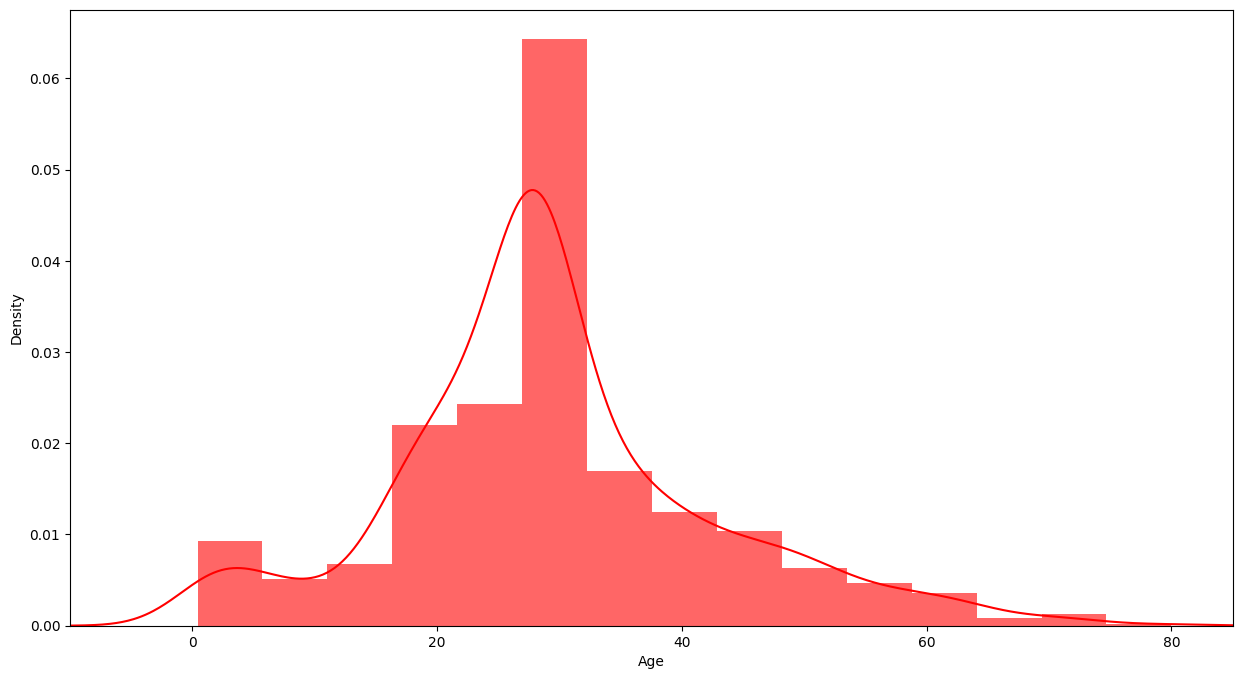

In [ ]:
print(train_data.isnull().sum())
display(train_data.head())
import matplotlib.pyplot as plt
plt.figure(figsize=(15,8))
ax = train_data["Age"].hist(bins=15, density=True, stacked=True, color="red", alpha=0.6)
train_data["Age"].plot(kind='density', color="red")
plt.xlabel('Age')
plt.xlim(-10, 85)
plt.show()